# Cross-modality comparison: RCC RNA and protein

Fit RNA and protein **independently** on 1,595 matched renal-cell-carcinoma spots, then compare the spatial structures. RNA retains 405 genes and protein retains 27 measurements; both models use $K=9$, seed 0 and spatial weight 0.05. No shared weights, feature-pair penalty or cross-assay information enters these two fits.

This differs from joint multi-omics deconvolution in the Tonsil tutorial. Here, agreement is evidence from separately fitted assays. A full-data component matching is suitable for figure layout; the manuscript's quantitative comparison instead learns matching on coordinate-defined training folds and scores held-out spots.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

**Progress output.** With `RUN_FIT=True`, fitting prints the initialization stage, periodic `objective` (loss) and KKT residuals, then the final iteration count, elapsed time and convergence status. `VERBOSE=False` suppresses these fitting messages. `finished` reports either `converged` or an explicit iteration-limit/nonconvergence outcome. The objective includes this model's reconstruction and active penalties; it is not PCC or ARI.

With `RUN_FIT=False`, the cell loads a complete previous fit and displays its **recorded** convergence status, iteration count and final objective from `reproduction/training_summary.csv`. These are saved training records, not live iterations. New fits may differ slightly from those historical values.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table, saved_fit_summary
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False

VERBOSE = True
print("Mode: full model fitting." if RUN_FIT else "Mode: load saved full fits; no new optimization.")


Mode: load saved full fits; no new optimization.


## 2. Load the paired locations and separate feature panels

### Public data and prepared inputs

Public source: [10x Xenium Protein FFPE Human Renal Carcinoma](https://www.10xgenomics.com/datasets/xenium-protein-ffpe-human-renal-carcinoma). The tutorial bundle contains the prepared paired matrices at 1,595 matched locations, with all 405 RNA genes and 27 protein measurements in this analysis. RNA and protein are fitted independently before their spatial structures are compared.

The [spDecon tutorial data release](https://github.com/dsong-lab/spDecon/releases/tag/tutorial-data-v0.1.0) packages the processed inputs and saved spDecon fits so that the code below reproduces the displayed outputs. Use the original source links for raw downloads and dataset terms.

In [2]:
path,data=dataset("rcc")
xy=data["coordinates"]
print("RNA:",data["Y_rna"].shape,"Protein:",data["Y_protein"].shape)

RNA: (1595, 405) Protein: (1595, 27)


## 3. Fit each assay without coupling

Retain the original nonnegative protein measurements. Each modality has its own exposure, initialization and expression profiles.

In [3]:
from spDecon.consensus import build_consensus
from spDecon.spatial import spatial_graph,refine
i,j,w,_=spatial_graph(xy,np.repeat("RCC",len(xy)))
fits={}
for assay in ["rna","protein"]:
    if RUN_FIT:
        print(f"[spDecon] Fitting RCC {assay}", flush=True)
        set_seed(0,deterministic=True)
        y=np.array(data["Y_"+assay],dtype=float,order="F")
        initial=build_consensus(y,9,random_state=0,verbose=VERBOSE)
        result=refine(y,initial.consensus_proportions,initial.consensus_profiles,i,j,w,.05,0,verbose=VERBOSE)
        fits[assay]=result.proportions
        print(assay,result.diagnostics)
    else:
        fits[assay]=np.load(path/(assay+".npz"))["P"]
        saved_fit_summary("rcc", assay)


[saved fit] rcc/rna loaded | recorded status=converged | outer_iterations=19 | objective=0.044101622
[saved fit] This cell loaded a previous full fit; no new optimization was run.


[saved fit] rcc/protein loaded | recorded status=converged | outer_iterations=42 | objective=0.0257689524
[saved fit] This cell loaded a previous full fit; no new optimization was run.


/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: Futur

## 4. Match structures for display and plot all components

The Hungarian assignment maximizes spatial proportion correlation over all 1,595 spots. Original RNA and protein component numbers remain in the titles. Correlations here are descriptive and are not the held-out manuscript score. Each map uses the same 0–1 weight scale.

,RNA_component,protein_component,display_PCC
0,1,8,0.593161
1,2,2,0.471057
2,3,7,0.860077
3,4,5,0.799464
4,5,9,0.597631
5,6,6,0.601480
6,7,3,0.988282
7,8,1,0.421978
8,9,4,0.868573


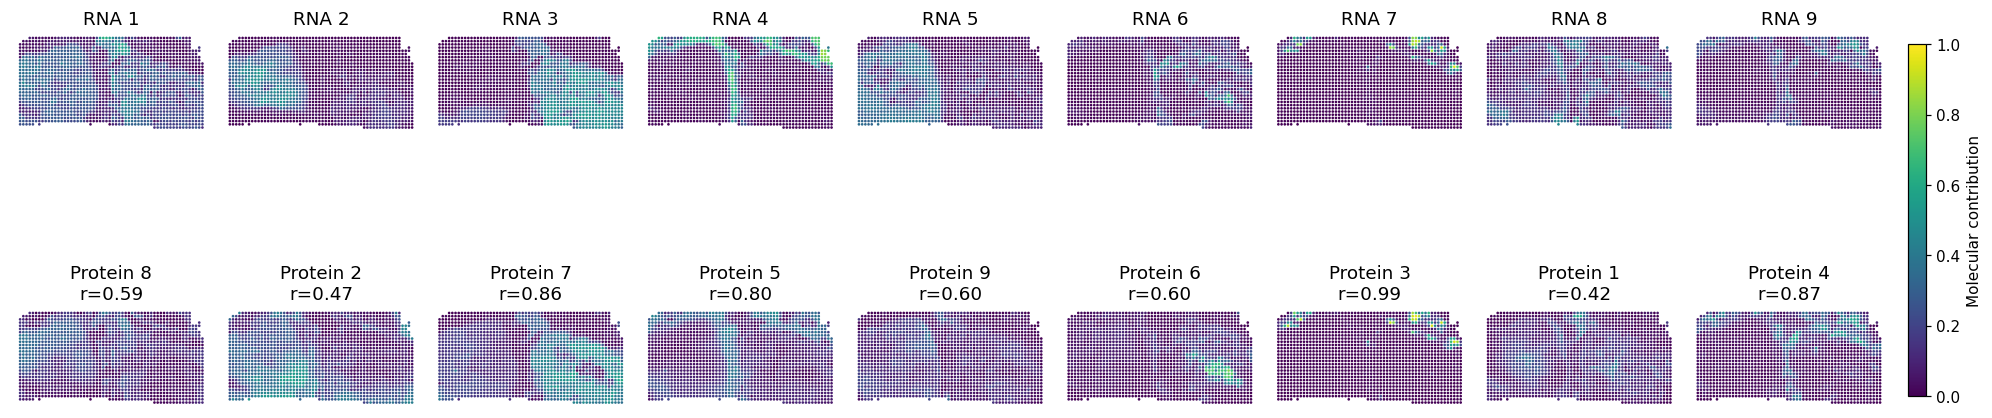

In [4]:
from scipy.optimize import linear_sum_assignment
matrix=correlation(fits["rna"],fits["protein"])
a,b=linear_sum_assignment(-matrix)
order=b[np.argsort(a)]
pairs=pd.DataFrame({"RNA_component":np.arange(1,10),"protein_component":order+1,
                    "display_PCC":matrix[np.arange(9),order]})
display(save_table(pairs,"rcc_display_matching"))
fig,axes=plt.subplots(2,9,figsize=(18,5),layout="constrained")
for k,j in enumerate(order):
    spatial(axes[0,k],xy,fits["rna"][:,k],f"RNA {k+1}",size=3)
    art=spatial(axes[1,k],xy,fits["protein"][:,j],f"Protein {j+1}\nr={matrix[k,j]:.2f}",size=3)
fig.colorbar(art,ax=axes,label="Molecular contribution",shrink=.65,pad=.01)
save_figure(fig,"rcc_structures")

## 5. Read the reproduction comparison

The saved full refits give held-out mean PCC 0.689139 versus archived 0.699004; deterministic solver replay gives 0.695808. All used seed 0. The residual difference is not explained by an omitted seed: initialization matched, while GPU numerical execution affected later optimization. These small differences are retained rather than replacing them with the manuscript values. The following table is from the complete four-fold evaluation, not recalculated from the display matching above.

In [5]:
report=pd.read_csv(path/"reproduction_metrics.csv")
display(report[["version","heldout_PCC","heldout_CCC","full_mass_TVD","dominant_ARI"]])

,version,heldout_PCC,heldout_CCC,full_mass_TVD,dominant_ARI
0,archived,0.699004,0.630819,0.320271,0.478393
1,rerun,0.689139,0.619695,0.325748,0.442971
2,deterministic_replay,0.695808,0.626879,0.321571,0.474851
